In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path
import nltk
pd.options.display.max_columns = 100


In [11]:
DATA_DIR = next(
    (
        folder / "data/k10plus"
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "k10plus" / "export.json").exists()
    ),
    None,
)
assert DATA_DIR is not None, "data/k10plus/export.json not found above the working directory"
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /home/jupyter-vojta/notebooks/biblical-books/data/k10plus


In [13]:
import pyarrow.parquet as pq

path = DATA_DIR / "books_21st_enggerfre.parquet"

# The file's pandas metadata records list columns as "list<element: string>[pyarrow]",
# which pandas feeds to np.dtype() and rejects. Drop the metadata, keep the data.
books_21st_enggerfre = pq.read_table(path).replace_schema_metadata(None).to_pandas()

print(books_21st_enggerfre.shape)
books_21st_enggerfre.dtypes.value_counts()

(78341, 44)


object    24
str       18
int32      1
bool       1
Name: count, dtype: int64

In [14]:
books_21st_enggerfre.head(10)

,record_id,source_url,leader,record_type,bibliographic_level,title,subtitle,full_title,responsibility,publication_statement,date_text,edition,extent,abstract,date_type,first_seen,last_seen,authors,editors,contributors,languages,isbns,issns,dois,publishers,publication_places,subjects,subject_authority_ids,ddc,lcc,other_classifications,series,urls,related_record_ids,notes,matched_queries,name_authority_ids,authority_ids,contributor_types,publication_year,is_textual_monograph,contributor_records,subjects_structured,title_cleaned
0,037895184,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=03...,cam a22 cc4500,a,m,Homélies sur le Lévitique Tome 1 (Homélies I -...,,Homélies sur le Lévitique Tome 1 (Homélies I -...,"Origène. Texte latin, introd., trad. et notes ...",Paris Éd. du Cerf 2008,2008,,374 Seiten,,s,2026-11-18T11:12:50.712900+00:00,2026-11-18T11:12:50.712900+00:00,[],[],"[Borret, Marcel, Origenes]","[fre, lat]",[220401799X],[],[],[Éd. du Cerf],[Paris],[],[],[222/.1306],[],[BO 1160 rvk (DE-625)rvk/13910:],[Sources chrétiennes 286],[],"[(DE-627)037143972, (DE-576)9037143970]",[],[ddc_bible],[118590235],[118590235],"[win, oth]",2008,True,"[{'sequence': 1, 'marc_tag': '700', 'is_primar...",[],homélie lévitique tome homélie i vii
1,071940871,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=07...,cam a22 2c 4500,a,m,Jesus Sirach,= Ben Sira,Jesus Sirach: = Ben Sira,übers. u. erkl. von Georg Sauer,Göttingen Vandenhoeck & Ruprecht 2000,2000,,351 S,,s,2026-11-18T11:35:51.345789+00:00,2026-11-18T14:52:58.855496+00:00,[],[],"[Sauer, Georg]",[ger],[3525514018],[],[],[Vandenhoeck & Ruprecht],[Göttingen],"[Bibel, Bible. // O.T. // Apocrypha. // Eccles...","[4055145-3, 4136710-8]",[],[BS1765.3],"[1 ssgn, BC 3000 rvk (DE-625)rvk/9326:, BC 400...",[Das Alte Testament Deutsch Apokryphen 1],[http://www.gbv.de/dms/hebis-mainz/toc/0911836...,[(DE-627)1797909061],[],"[lcc_bible, subject_bibel, subject_old_testament]",[119022400],"[119022400, 4055145-3, 4136710-8]",[oth],2000,True,"[{'sequence': 1, 'marc_tag': '700', 'is_primar...","[{'sequence': 1, 'marc_tag': '630', 'entity_ty...",jesus sirach
2,071941827,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=07...,cam a22 2c 4500,a,m,Psalmen 51 - 100,,Psalmen 51 - 100,übers. u. ausgelegt von Frank-Lothar Hossfeld ...,Freiburg [u.a.] Herder 2000,2000,,727 S Ill. 24 cm,,s,2026-11-18T11:15:56.672700+00:00,2026-11-18T14:13:05.695629+00:00,"[Hossfeld, Frank-Lothar]",[],"[Hossfeld, Frank-Lothar, Zenger, Erich]",[ger],[3451268264],[],[],[Herder],[Freiburg [u.a.]],[Bible Commentaries],"[4364883-6, 4136710-8]",[223/.2077],[BS1425],"[6,22 ssgn, BC 4000 BVB rvk (DE-625)rvk/9399:,...",[Herders theologischer Kommentar zum Alten Tes...,[http://d-nb.info/959597395/04],[],[],"[ddc_bible, lcc_bible, subject_bibel, subject_...",[],"[4364883-6, 4136710-8]",[aut],2000,True,"[{'sequence': 1, 'marc_tag': '100', 'is_primar...","[{'sequence': 1, 'marc_tag': '630', 'entity_ty...",psalme
3,071942297,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=07...,cam a22 c 4500,a,m,Die schönsten Geschichten der Bibel,,Die schönsten Geschichten der Bibel,Nico ter Linden. Aus dem Niederländ. übers.,Gütersloh Gütersloher Verlagshaus 2002,2002,,157 S.,,s,2026-11-18T12:38:13.306749+00:00,2026-11-18T12:38:13.306749+00:00,"[Linden, Nico ter]",[],"[Linden, Nico ter]",[ger],[3579013327],[],[],[Gütersloher Verlagshaus],[Gütersloh],[Bibel],"[4006406-2, 4049422-6]",[],[],[1 ssgn],[Gütersloher Taschenbücher Siebenstern 1332],[],[],[],[subject_bibel],[120514885],"[120514885, 4006406-2, 4049422-6]",[aut],2002,True,"[{'sequence': 1, 'marc_tag': '100', 'is_primar...","[{'sequence': 1, 'marc_tag': '630', 'entity_ty...",schön geschichte bibel
4,071942467,https://opac.k10plus.de/DB=2.299/PPNSET?PPN=07...,cam a22 c 4500,a,m,Meersburger Bibelquiz,"6 Schwierigkeitsstufen, für 1-2 Spieler, 1111 ...","Meersburger Bibelquiz: 6 Schwierigkeitsstufen,...",,Marienheide Bibellesebund [u.a.] 2000,2000,Für Mac & PC,1 CD-ROM 12 cm,,s,2026-11-18T12:44:42.521896+00:00,2026-11-18T12:44:42.52

In [30]:
import ast

def parse_list(value):
    """Normalise a list-like cell value (string or existing sequence) into a list."""
    if value is None:
        return []
    if isinstance(value, (bytes, bytearray)):
        value = value.decode("utf-8", "replace")
    if not isinstance(value, str):
        return list(value)          # already list / tuple / ndarray
    text = value.replace("\x00", "").strip()   # <- fixes the null-byte SyntaxError
    if not text:
        return []
    try:
        parsed = ast.literal_eval(text)
    except (ValueError, SyntaxError):
        return [p.strip().strip("'\"") for p in text.strip("[]").split(",") if p.strip()]
    return list(parsed) if isinstance(parsed, (list, tuple, set)) else [parsed]

books_21st_enggerfre["languages"] = books_21st_enggerfre["languages"].apply(parse_list)
books_21st_enggerfre["languages"].head()

0    [fre, lat]
1         [ger]
2         [ger]
3         [ger]
4         [ger]
Name: languages, dtype: object

In [31]:
books_21st_enggerfre["language_first"] = books_21st_enggerfre["languages"].apply(lambda x: x[0])

In [32]:
books_21st_enggerfre["language_first"].value_counts()

language_first
eng    45876
ger    29227
fre     3238
Name: count, dtype: int64

In [38]:
books_21st_enggerfre.columns

Index(['record_id', 'source_url', 'leader', 'record_type',
       'bibliographic_level', 'title', 'subtitle', 'full_title',
       'responsibility', 'publication_statement', 'date_text', 'edition',
       'extent', 'abstract', 'date_type', 'first_seen', 'last_seen', 'authors',
       'editors', 'contributors', 'languages', 'isbns', 'issns', 'dois',
       'publishers', 'publication_places', 'subjects', 'subject_authority_ids',
       'ddc', 'lcc', 'other_classifications', 'series', 'urls',
       'related_record_ids', 'notes', 'matched_queries', 'name_authority_ids',
       'authority_ids', 'contributor_types', 'publication_year',
       'is_textual_monograph', 'contributor_records', 'subjects_structured',
       'title_cleaned', 'language_first'],
      dtype='str')

In [35]:
books_sample = books_21st_enggerfre[books_21st_enggerfre["language_first"]=="eng"]
len(books_sample)

45876

In [36]:
nltk.FreqDist(" ".join(books_sample["title_cleaned"].tolist()).split()).most_common(20)

[('bible', 3996),
 ('biblical', 2916),
 ('testament', 2278),
 ('new', 2029),
 ('gospel', 1867),
 ('paul', 1674),
 ('book', 1509),
 ('god', 1494),
 ('jesus', 1391),
 ('hebrew', 1367),
 ('john', 1073),
 ('scripture', 1032),
 ('early', 1018),
 ('old', 938),
 ('theology', 937),
 ('commentary', 933),
 ('ancient', 920),
 ('christian', 894),
 ('text', 823),
 ('study', 786)]

In [39]:
data_samples = {
    "eng_2000-2009": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="eng") & (books_21st_enggerfre["publication_year"] >= 2000) & (books_21st_enggerfre["publication_year"] < 2010)],
    "eng_2010-2019": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="eng") & (books_21st_enggerfre["publication_year"] >= 2010) & (books_21st_enggerfre["publication_year"] < 2020)],
    "eng_2020-2026": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="eng") & (books_21st_enggerfre["publication_year"] >= 2020) & (books_21st_enggerfre["publication_year"] < 2027)], 
    "ger_2000-2009": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="ger") & (books_21st_enggerfre["publication_year"] >= 2000) & (books_21st_enggerfre["publication_year"] < 2010)],
    "ger_2010-2019": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="ger") & (books_21st_enggerfre["publication_year"] >= 2010) & (books_21st_enggerfre["publication_year"] < 2020)],
    "ger_2020-2026": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="ger") & (books_21st_enggerfre["publication_year"] >= 2020) & (books_21st_enggerfre["publication_year"] < 2027)],  
    "fre_2000-2009": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="fre") & (books_21st_enggerfre["publication_year"] >= 2000) & (books_21st_enggerfre["publication_year"] < 2010)],
    "fre_2010-2019": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="fre") & (books_21st_enggerfre["publication_year"] >= 2010) & (books_21st_enggerfre["publication_year"] < 2020)],
    "fre_2020-2026": books_21st_enggerfre[(books_21st_enggerfre["language_first"]=="fre") & (books_21st_enggerfre["publication_year"] >= 2020) & (books_21st_enggerfre["publication_year"] < 2027)],
}

In [40]:
for sample in data_samples:
    print(f"{sample}: {len(data_samples[sample])} books")

eng_2000-2009: 13295 books
eng_2010-2019: 19666 books
eng_2020-2026: 12880 books
ger_2000-2009: 10588 books
ger_2010-2019: 12130 books
ger_2020-2026: 6502 books
fre_2000-2009: 1258 books
fre_2010-2019: 1213 books
fre_2020-2026: 767 books


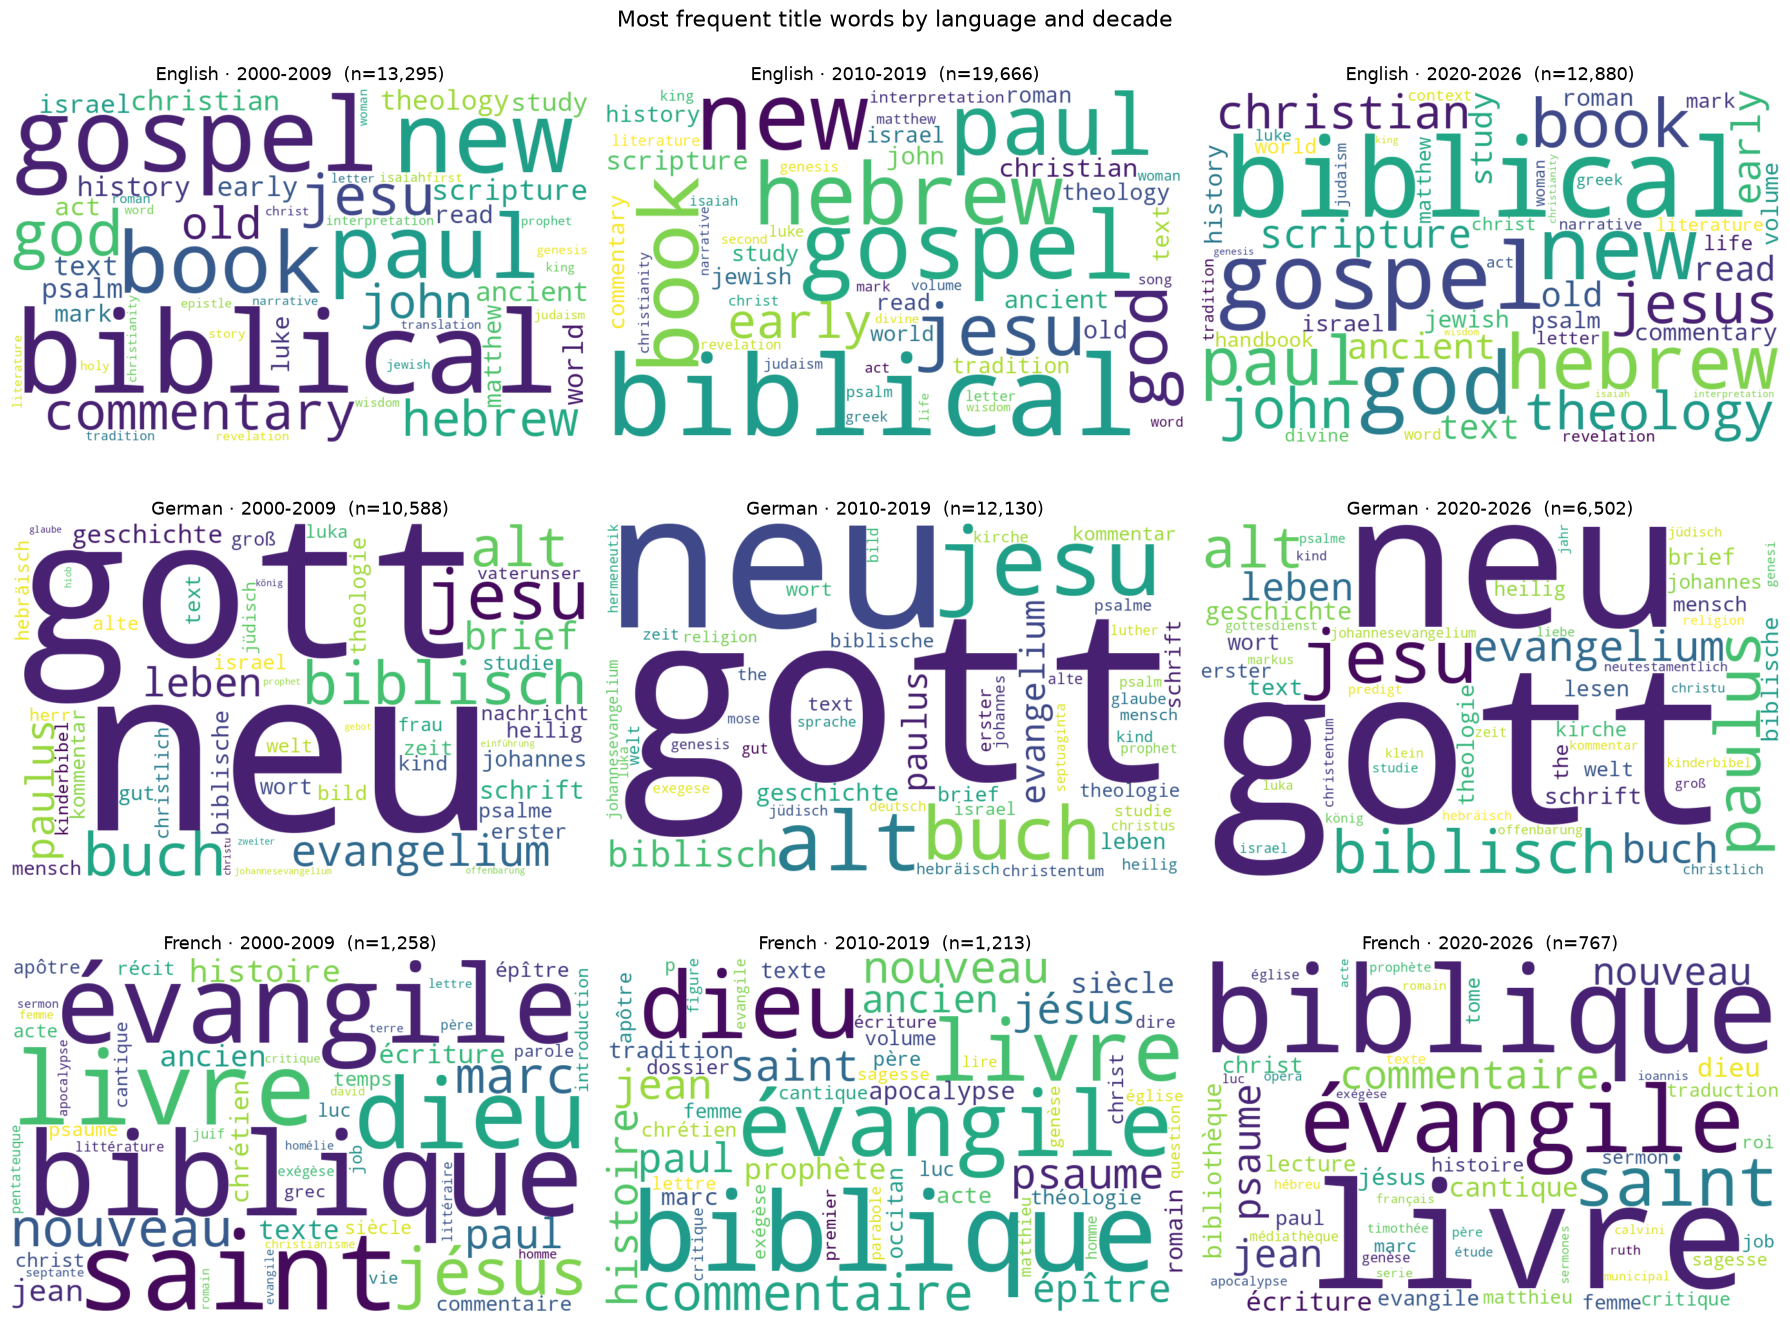

In [43]:
from nltk.corpus import stopwords as nltk_stopwords

from wordcloud import WordCloud   # pip install wordcloud  if missing

# Per-language stopwords; falls back to an empty set if the nltk corpora are absent
try:
    STOPWORDS = {
        "eng": set(nltk_stopwords.words("english")),
        "ger": set(nltk_stopwords.words("german")),
        "fre": set(nltk_stopwords.words("french")),
    }
except Exception:
    STOPWORDS = {"eng": set(), "ger": set(), "fre": set()}

# Domain noise that would otherwise dominate every panel
COMMON_NOISE = {"bibel", "bible", "testament", "band", "bd", "vol", "edition"}
STOPWORDS = {lang: words | COMMON_NOISE for lang, words in STOPWORDS.items()}

LANGS = ["eng", "ger", "fre"]
LANG_NAMES = {"eng": "English", "ger": "German", "fre": "French"}
DECADES = ["2000-2009", "2010-2019", "2020-2026"]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))

for row, lang in enumerate(LANGS):
    for col, decade in enumerate(DECADES):
        key = f"{lang}_{decade}"
        ax = axes[row, col]

        titles = data_samples[key]["title_cleaned"].dropna().astype(str)
        text = " ".join(titles)

        if text.strip():
            wc = WordCloud(
                width=900, height=550,
                background_color="white",
                stopwords=STOPWORDS[lang],
                collocations=False,      # titles are already short; avoid bigram blobs
                max_words=50,
                random_state=42,
            ).generate(text)
            ax.imshow(wc, interpolation="bilinear")
        else:
            ax.text(0.5, 0.5, "no titles", ha="center", va="center", fontsize=12)

        ax.set_title(f"{LANG_NAMES[lang]} · {decade}  (n={len(titles):,})", fontsize=13)
        ax.axis("off")

fig.suptitle("Most frequent title words by language and decade", fontsize=16)
fig.tight_layout()
plt.show()

In [44]:
fig.savefig("../figures/wordclouds_by_language_decade.png", dpi=300)